# P57: dev_medium_b vs dev_medium_clean

Overfit check and stratification comparison. Reads only committed files: the two manifests, the noise table
and the `_v8` baseline tables (`benchmarks/baselines/*_v8_tables/per_star.csv`). Writes `figures/` and `data/`.

In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import fisher_exact

def proportion_confint(k, n, method='wilson', z=1.959963984540054):
    """Wilson score 95% interval for k successes in n trials."""
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return c - h, c + h

REPO = Path.cwd()
while not (REPO / 'datasets').is_dir():
    REPO = REPO.parent
REP = REPO / 'reports' / '2026-11-20_p57-dev-medium-b'
FIG, DATA = REP / 'figures', REP / 'data'
FIG.mkdir(exist_ok=True); DATA.mkdir(exist_ok=True)
BL = REPO / 'benchmarks' / 'baselines'
SETS = {'dev_medium_clean': 'A: dev_medium_clean', 'dev_medium_b_clean': 'B: dev_medium_b_clean'}
COL = {'dev_medium_clean': '#4C72B0', 'dev_medium_b_clean': '#DD8452'}
man = {k: pd.read_csv(REPO / 'datasets' / f'{k}.csv') for k in SETS}
ps = {(k, m): pd.read_csv(BL / f'{k}_{m}_v8_tables' / 'per_star.csv') for k in SETS for m in ('fullyear', 'assigned')}
noise = pd.read_csv(REPO / 'benchmarks' / 'noise_sources_dev.csv').set_index('sim_id')
# noise classes from the drive's CURRENT flags file (2026-11-10 update); the committed table keeps pre-update labels
# for dev_medium stars (all 'quiet'), so class mixes are compared with this snapshot instead
nclass = pd.read_csv(DATA / 'noise_class_current_flags.csv').set_index('sim_id').noise_class_current
CAT = {'success': ('correct', 'diffrot'), 'alias': ('half', 'double'), 'wrong': ('wrong',)}
BINS = ['<1d', '1-3d', '3-10d', '10-30d', '>30d']
{k: len(v) for k, v in man.items()}

{'dev_medium_clean': 874, 'dev_medium_b_clean': 1000}

## Overall and per-bin rates with Wilson 95% CIs; Fisher exact p for A vs B

In [2]:
def rates(df):
    out = {}
    n = len(df)
    for c, outs in CAT.items():
        k = int(df.final_outcome.isin(outs).sum())
        lo, hi = proportion_confint(k, n, method='wilson') if n else (np.nan, np.nan)
        out[c] = (k, n, k / n if n else np.nan, lo, hi)
    return out

rows = []
for mode in ('fullyear', 'assigned'):
    for b in ['all'] + BINS:
        rec = {'mode': mode, 'bin': b}
        cnt = {}
        for s in SETS:
            d = ps[(s, mode)]
            d = d if b == 'all' else d[d.period_bin == b]
            for c, (k, n, r, lo, hi) in rates(d).items():
                tag = 'A' if s == 'dev_medium_clean' else 'B'
                rec.update({f'{tag}_n': n, f'{tag}_{c}': r, f'{tag}_{c}_lo': lo, f'{tag}_{c}_hi': hi})
                cnt[(tag, c)] = (k, n)
        for c in CAT:
            (ka, na), (kb, nb) = cnt[('A', c)], cnt[('B', c)]
            rec[f'p_{c}'] = fisher_exact([[ka, na - ka], [kb, nb - kb]])[1]
        rows.append(rec)
comp = pd.DataFrame(rows)
comp.to_csv(DATA / 'rates_A_vs_B.csv', index=False)
show = comp[['mode', 'bin', 'A_n', 'B_n', 'A_success', 'B_success', 'p_success', 'A_alias', 'B_alias', 'p_alias',
             'A_wrong', 'B_wrong', 'p_wrong']]
show.round(3)

,mode,bin,A_n,B_n,A_success,B_success,p_success,A_alias,B_alias,p_alias,A_wrong,B_wrong,p_wrong
0,fullyear,all,874,1000,0.265,0.274,0.715,0.009,0.010,1.000,0.024,0.034,0.219
1,fullyear,<1d,148,172,0.209,0.215,1.000,0.007,0.000,0.462,0.000,0.023,0.127
2,fullyear,1-3d,149,172,0.255,0.273,0.800,0.000,0.000,1.000,0.027,0.006,0.187
3,fullyear,3-10d,151,171,0.318,0.310,0.905,0.000,0.000,1.000,0.000,0.029,0.063
4,fullyear,10-30d,151,171,0.358,0.456,0.088,0.000,0.000,1.000,0.026,0.029,1.000
5,fullyear,>30d,275,314,0.222,0.188,0.356,0.025,0.032,0.806,0.047,0.061,0.586
6,assigned,all,874,1000,0.153,0.167,0.449,0.006,0.002,0.262,0.030,0.020,0.181
7,assigned,<1d,148,172,0.216,0.238,0.689,0.000,0.000,1.000,0.007,0.017,0.627
8,assigned,1-3d,149,172,0.221,0.209,0.892,0.007,0.000,0.464,0.027,0.029,1.000
9,assigned,3-10d,151,171,0.192,0.211,0.781,0.000,0.006,1.000,0.013,0.018,1.000


### Figure 1: per-bin success / alias / wrong, both sets side by side

Bars are rates, whiskers Wilson 95% CIs. Top row full-year, bottom row assigned coverage.

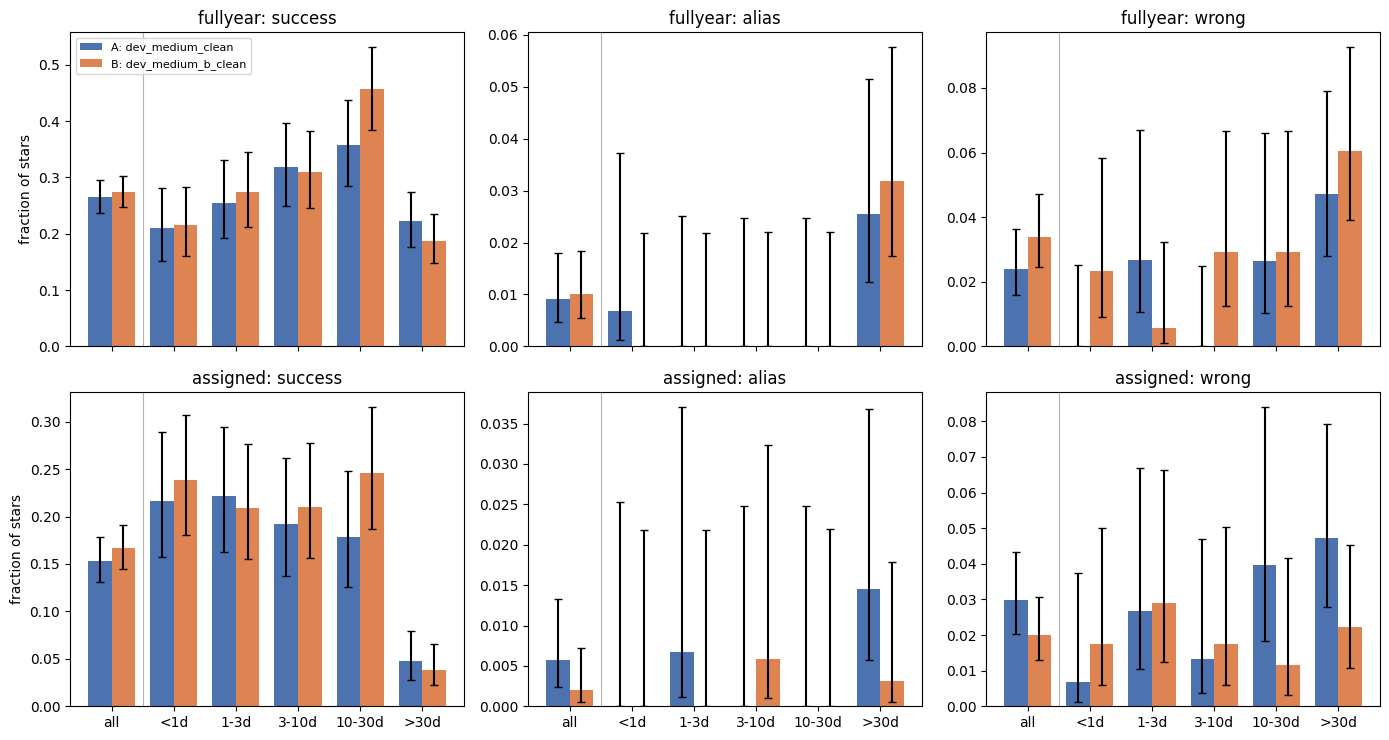

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5), sharex=True)
x = np.arange(len(BINS) + 1); labels = ['all'] + BINS; w = 0.38
for i, mode in enumerate(('fullyear', 'assigned')):
    c = comp[comp['mode'] == mode].set_index('bin').loc[labels]
    for j, cat in enumerate(CAT):
        ax = axes[i, j]
        for off, tag, s in ((-w / 2, 'A', 'dev_medium_clean'), (w / 2, 'B', 'dev_medium_b_clean')):
            r = c[f'{tag}_{cat}'].to_numpy()
            err = np.clip([r - c[f'{tag}_{cat}_lo'].to_numpy(), c[f'{tag}_{cat}_hi'].to_numpy() - r], 0, None)
            ax.bar(x + off, r, w, yerr=err, capsize=3, color=COL[s], label=SETS[s])
        for xi, p in zip(x, c[f'p_{cat}']):
            if p < 0.05:
                ax.annotate(f'p={p:.3f}', (xi, ax.get_ylim()[1] * 0.92), ha='center', fontsize=8, color='crimson')
        ax.set_title(f'{mode}: {cat}'); ax.set_xticks(x, labels)
        ax.axvline(0.5, color='0.7', lw=0.8)
        if j == 0: ax.set_ylabel('fraction of stars')
axes[0, 0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'fig1_bins_A_vs_B.png', dpi=130)

### Figure 2: stratification comparison

Period, amplitude proxy, coverage class (assigned), shear class, number of native sectors, and the noise-source class
mix (current T20 flags, `data/noise_class_current_flags.csv`). Densities / fractions, so the different set sizes (874 vs 1,000) don't matter.

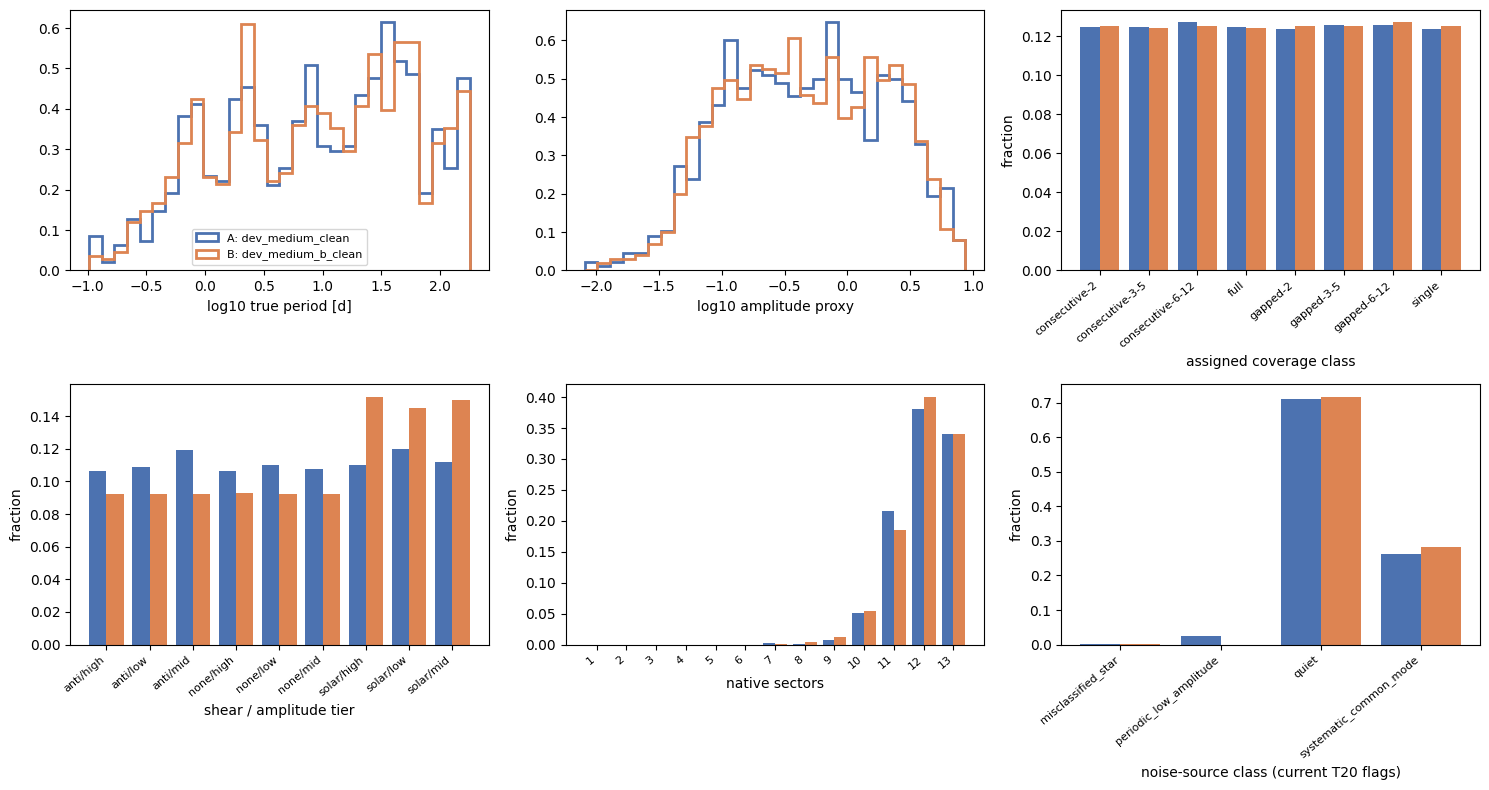

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
A, B = man['dev_medium_clean'], man['dev_medium_b_clean']
def hist(ax, col, f=lambda v: v, bins=30, xlabel=None):
    lo = min(f(A[col]).min(), f(B[col]).min()); hi = max(f(A[col]).max(), f(B[col]).max())
    e = np.linspace(lo, hi, bins + 1)
    for s, d in (('dev_medium_clean', A), ('dev_medium_b_clean', B)):
        ax.hist(f(d[col]), e, density=True, histtype='step', lw=2, color=COL[s], label=SETS[s])
    ax.set_xlabel(xlabel or col)
def bars(ax, series, order=None, xlabel=''):
    fa = series(A).value_counts(normalize=True); fb = series(B).value_counts(normalize=True)
    order = order or sorted(set(fa.index) | set(fb.index))
    xx = np.arange(len(order))
    ax.bar(xx - 0.2, fa.reindex(order).fillna(0), 0.4, color=COL['dev_medium_clean'], label=SETS['dev_medium_clean'])
    ax.bar(xx + 0.2, fb.reindex(order).fillna(0), 0.4, color=COL['dev_medium_b_clean'], label=SETS['dev_medium_b_clean'])
    ax.set_xticks(xx, order, rotation=40, ha='right', fontsize=8); ax.set_xlabel(xlabel); ax.set_ylabel('fraction')
hist(axes[0, 0], 'true_period', np.log10, xlabel='log10 true period [d]')
hist(axes[0, 1], 'amp_proxy', lambda v: np.log10(v.clip(1e-3)), xlabel='log10 amplitude proxy')
bars(axes[0, 2], lambda d: d.coverage_class, xlabel='assigned coverage class')
bars(axes[1, 0], lambda d: d.shear_class + '/' + d.amp_tier, xlabel='shear / amplitude tier')
bars(axes[1, 1], lambda d: d.n_native_sectors.astype(str), order=[str(i) for i in range(1, 14)], xlabel='native sectors')
bars(axes[1, 2], lambda d: nclass.loc[d.sim_id].reset_index(drop=True), xlabel='noise-source class (current T20 flags)')
axes[0, 0].legend(fontsize=8); fig.tight_layout(); fig.savefig(FIG / 'fig2_stratification.png', dpi=130)

In [5]:
# per-bin counts and a few scalar comparisons
cnt = pd.concat({SETS[k]: v.groupby('pbin').size() for k, v in man.items()}, axis=1)
extra = pd.DataFrame({SETS[k]: {
    'n': len(v), 'median P': v.true_period.median(), 'median amp_proxy': v.amp_proxy.median(),
    'frac noise systematic_common_mode': (nclass.loc[v.sim_id] == 'systematic_common_mode').mean(),
    'frac noise periodic_low_amplitude (coherent-quiet)': (nclass.loc[v.sim_id] == 'periodic_low_amplitude').mean(),
    'n noise TICs': noise.loc[v.sim_id, 'tic'].nunique(),
    'median n_native_sectors': v.n_native_sectors.median()} for k, v in man.items()})
cnt.to_csv(DATA / 'pbin_counts.csv'); extra.to_csv(DATA / 'set_summary.csv')
display(cnt); extra

,A: dev_medium_clean,B: dev_medium_b_clean
pbin,,
1-3d,149,172
10-30d,151,171
120-180d,61,71
3-10d,151,171
30-60d,149,171
60-120d,65,72
<1d,148,172


,A: dev_medium_clean,B: dev_medium_b_clean
n,874.000000,1000.000000
median P,9.394450,9.553350
median amp_proxy,0.487131,0.456371
frac noise systematic_common_mode,0.262014,0.281000
frac noise periodic_low_amplitude (coherent-quiet),0.025172,0.000000
n noise TICs,447.000000,472.000000
median n_native_sectors,12.000000,12.000000


In [6]:
# noise-TIC overlap between the sets
tA = set(noise.loc[A.sim_id, 'tic']); tB = noise.loc[B.sim_id, 'tic']
print(f'B uses {tB.nunique()} noise TICs; {len(set(tB) & tA)} also serve dev_medium_clean stars; '
      f'{int(tB.isin(tA).sum())} of {len(B)} B stars sit on such a TIC')

B uses 472 noise TICs; 359 also serve dev_medium_clean stars; 762 of 1000 B stars sit on such a TIC


### The < 1 d bin of B is all solar shear

The < 1 d anti / none cells of the >= 800k pool are used up by dev_small + dev_medium + holdout (0 eligible rows), so the
T2 water-filling put all 172 B stars into the three solar cells. Same-shear comparison: A's < 1 d solar stars vs B's.

In [7]:
rows = []
for mode in ('fullyear', 'assigned'):
    for s in SETS:
        d = ps[(s, mode)].merge(man[s][['star_id', 'shear_class', 'pbin']], on='star_id')
        d = d[d.pbin == '<1d']
        for sh, g in d.groupby('shear_class'):
            k = int(g.final_outcome.isin(CAT['success']).sum()); lo, hi = proportion_confint(k, len(g))
            rows.append(dict(mode=mode, set=SETS[s], shear=sh, n=len(g), success=k / len(g), lo=lo, hi=hi,
                             diffrot=float((g.final_outcome == 'diffrot').mean()), wrong=float((g.final_outcome == 'wrong').mean())))
lt1 = pd.DataFrame(rows); lt1.to_csv(DATA / 'lt1d_by_shear.csv', index=False); lt1.round(3)

,mode,set,shear,n,success,lo,hi,diffrot,wrong
0,fullyear,A: dev_medium_clean,anti,51,0.157,0.082,0.280,0.059,0.000
1,fullyear,A: dev_medium_clean,none,45,0.244,0.142,0.387,0.000,0.000
2,fullyear,A: dev_medium_clean,solar,52,0.231,0.137,0.361,0.077,0.000
3,fullyear,B: dev_medium_b_clean,solar,172,0.215,0.160,0.282,0.041,0.023
4,assigned,A: dev_medium_clean,anti,51,0.196,0.110,0.325,0.059,0.020
5,assigned,A: dev_medium_clean,none,45,0.244,0.142,0.387,0.000,0.000
6,assigned,A: dev_medium_clean,solar,52,0.212,0.122,0.340,0.077,0.000
7,assigned,B: dev_medium_b_clean,solar,172,0.238,0.181,0.307,0.076,0.017


### Figure 3: measured vs true period, dev_medium_b (full-year and assigned)

Answered stars only, coloured by outcome; dashed lines at P_true/2 and 2 P_true.

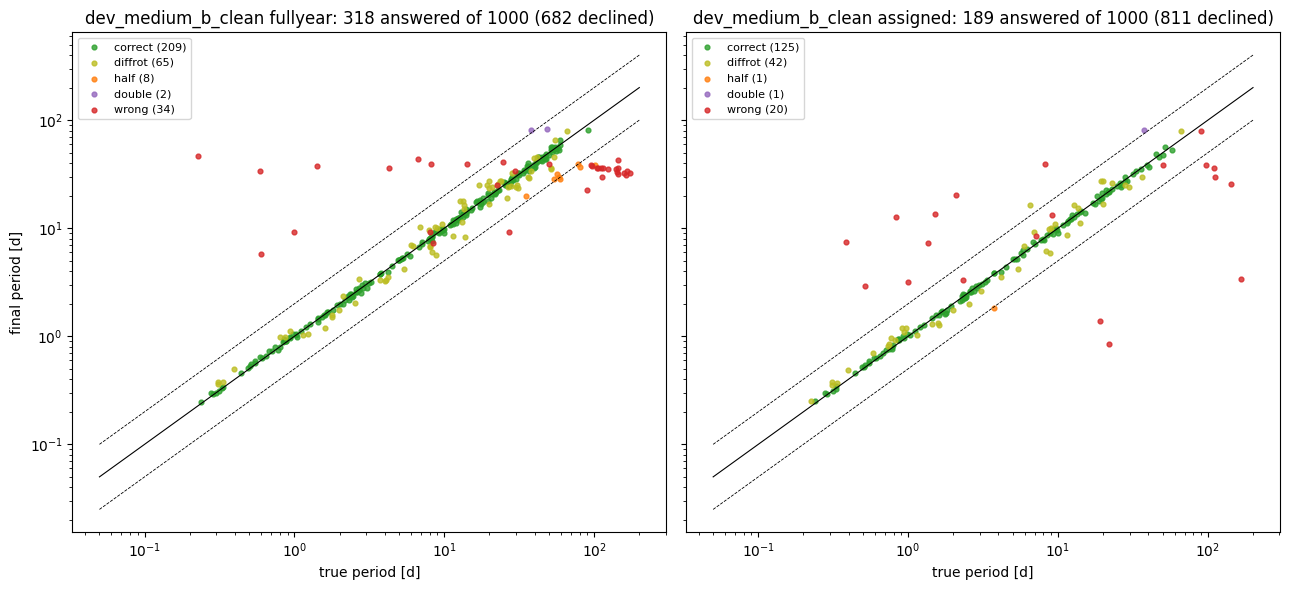

In [8]:
oc = {'correct': 'tab:green', 'diffrot': 'tab:olive', 'half': 'tab:orange', 'double': 'tab:purple', 'wrong': 'tab:red'}
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
for ax, mode in zip(axes, ('fullyear', 'assigned')):
    d = ps[('dev_medium_b_clean', mode)]
    a = d[d.final_outcome != 'none']
    for o, c in oc.items():
        s = a[a.final_outcome == o]
        ax.scatter(s.true_period, s.final_period, s=12, c=c, label=f'{o} ({len(s)})', alpha=0.8)
    g = np.geomspace(0.05, 200, 10)
    ax.plot(g, g, 'k-', lw=0.8); ax.plot(g, g / 2, 'k--', lw=0.6); ax.plot(g, 2 * g, 'k--', lw=0.6)
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('true period [d]')
    ax.set_title(f'dev_medium_b_clean {mode}: {len(a)} answered of {len(d)} ({(d.final_outcome=="none").sum()} declined)')
    ax.legend(fontsize=8, loc='upper left')
axes[0].set_ylabel('final period [d]')
fig.tight_layout(); fig.savefig(FIG / 'fig3_scatter_B.png', dpi=130)

### Figure 4: success by assigned coverage class, both sets (assigned mode)

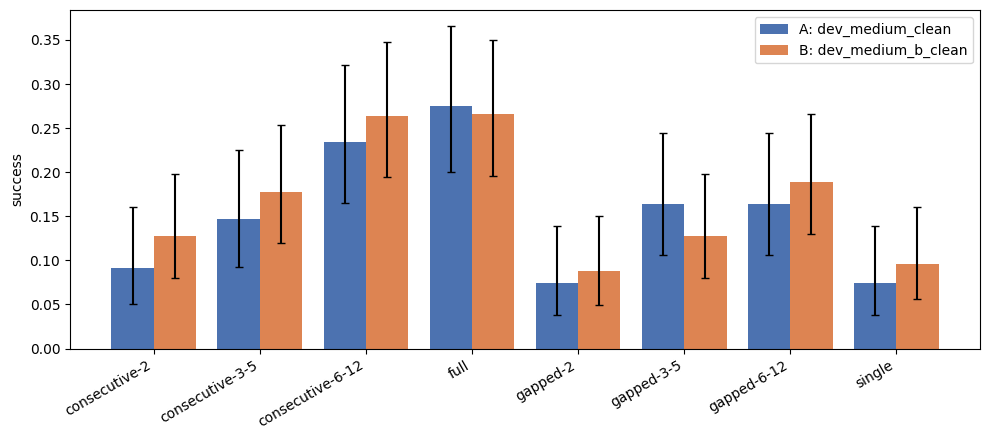

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.5))
classes = sorted(ps[('dev_medium_clean', 'assigned')].coverage_class.unique())
xx = np.arange(len(classes))
for off, s in ((-0.2, 'dev_medium_clean'), (0.2, 'dev_medium_b_clean')):
    d = ps[(s, 'assigned')]
    r, lo, hi = [], [], []
    for c in classes:
        sub = d[d.coverage_class == c]; k = int(sub.final_outcome.isin(CAT['success']).sum()); n = len(sub)
        l, h = proportion_confint(k, n, method='wilson'); r.append(k / n); lo.append(k / n - l); hi.append(h - k / n)
    ax.bar(xx + off, r, 0.4, yerr=np.clip([lo, hi], 0, None), capsize=3, color=COL[s], label=SETS[s])
ax.set_xticks(xx, classes, rotation=30, ha='right'); ax.set_ylabel('success'); ax.legend()
fig.tight_layout(); fig.savefig(FIG / 'fig4_coverage_success.png', dpi=130)

### Weighted (corpus-level) rates: `combined_weight` from each manifest

In [10]:
wr = []
for mode in ('fullyear', 'assigned'):
    for s in SETS:
        d = ps[(s, mode)].merge(man[s][['star_id', 'sampling_weight', 'combined_weight']], on='star_id')
        wcol = 'sampling_weight' if mode == 'fullyear' else 'combined_weight'
        w = d[wcol] / d[wcol].sum()
        wr.append(dict(mode=mode, set=SETS[s], weight=wcol, **{c: float((w * d.final_outcome.isin(o)).sum()) for c, o in CAT.items()}))
wr = pd.DataFrame(wr); wr.to_csv(DATA / 'weighted_rates.csv', index=False); wr.round(3)

,mode,set,weight,success,alias,wrong
0,fullyear,A: dev_medium_clean,sampling_weight,0.138,0.024,0.074
1,fullyear,B: dev_medium_b_clean,sampling_weight,0.129,0.022,0.085
2,assigned,A: dev_medium_clean,combined_weight,0.013,0.001,0.038
3,assigned,B: dev_medium_b_clean,combined_weight,0.018,0.000,0.006
